# Ejercicio 2: Regresión lineal múltiple — ADVERTISE

## Enunciado

Una empresa que elabora productos de consumo quiere medir la eficacia que tienen distintos tipos de medios publicitarios respecto a sus productos. La empresa se interesa específicamente en la eficacia de la publicidad en radio y en periódicos (incluyendo el costo de cupones de descuento). Se selecciona una muestra compuesta por 22 ciudades con población aproximadamente igual, para estudiarla durante un periodo de prueba de un mes. A cada ciudad se le asigna una cantidad de gastos específicos para publicidad en radio y periódicos. Se registraron las ventas de producto (en miles de dólares) y también los niveles medios de gastos (en miles de dólares) durante el mes de prueba, con los resultados del archivo `../Docs/ADVERTISE.xls`.

**Pregunta:** Elabore una estimación del intervalo de confianza para la media de las ventas correspondientes a las ciudades en las que la publicidad en radio alcanzó USD 20,000 y la publicidad en periódicos también fue de USD 20,000.

## Resolución paso a paso

1. **Definir variables y unidades.** La respuesta `Ventas` es el valor de ventas de producto, medido en miles de dólares. Las variables explicativas son `Radio` y `Periodico`, también en miles de dólares. La muestra contiene 22 ciudades.
2. **Convertir el punto solicitado.** Cada medio tuvo USD 20,000 de gasto; por tanto, como los gastos están en miles, el punto a evaluar es `Radio = 20` y `Periodico = 20`.
3. **Ajustar el modelo múltiple.** Se usa $Ventas_i = \beta_0 + \beta_1 Radio_i + \beta_2 Periodico_i + \varepsilon_i$. Los coeficientes se estiman por mínimos cuadrados, minimizando la suma de los residuos al cuadrado.
4. **Construir el intervalo para la media.** Se calcula la venta media estimada en el punto (20, 20) y el intervalo de confianza bilateral del 95% con la distribución t y $22-3=19$ grados de libertad residuales. Este es un intervalo para la **media** de las ventas bajo esos niveles de publicidad; un intervalo de predicción para las ventas de una ciudad individual sería más ancho.
5. **Interpretar resultados y revisar gráficos.** Los coeficientes describen el cambio asociado a cada medio manteniendo fijo el gasto en el otro. Los gráficos de dispersión y de residuos ayudan a revisar visualmente el ajuste y los supuestos de linealidad, varianza aproximadamente constante y normalidad de los errores. La independencia depende del diseño del estudio. El análisis estima asociaciones, no prueba causalidad.

El intervalo de confianza depende de que el modelo lineal y sus supuestos sean razonables. Los gráficos son diagnósticos y no sustituyen el conocimiento del diseño ni garantizan que se cumplan esos supuestos.

Archivo: C:\Users\Gasti\Desktop\MPG\Docs\ADVERTISE.xls
Ciudades: 22
Ventas y gastos publicitarios están expresados en miles de USD.


,Ventas,Radio,Periodico
0,973,0,40
1,1119,0,40
2,875,25,25
3,625,25,25
4,910,30,30


,count,mean,std,min,25%,50%,75%,max
Ventas,22.0,1225.136364,345.570101,625.0,941.00,1148.0,1499.75,1866.0
Radio,22.0,43.181818,19.793304,0.0,31.25,45.0,58.75,70.0
Periodico,22.0,30.000000,11.751393,0.0,25.00,30.0,38.75,45.0


,Coeficiente,Error estándar,t,p-valor
Intercepto,156.430435,126.757856,1.234089,2.322173e-01
Radio (miles de USD),13.080681,1.759374,7.434851,4.888606e-07
Periodico (miles de USD),16.795278,2.963378,5.667613,1.830691e-05


R² = 0.8087 | R² ajustado = 0.7886 | Error estándar residual = 158.904 miles de USD
Ecuación estimada: Ventas_hat = 156.4304 + 13.0807·Radio + 16.7953·Periodico

RESULTADO: Radio = USD 20,000 y Periódico = USD 20,000
Venta media estimada: 753.950 miles de USD = USD 753,949.62
IC del 95% para la media: [623.038, 884.861] miles de USD
En dólares: [USD 623,038.35, USD 884,860.88]


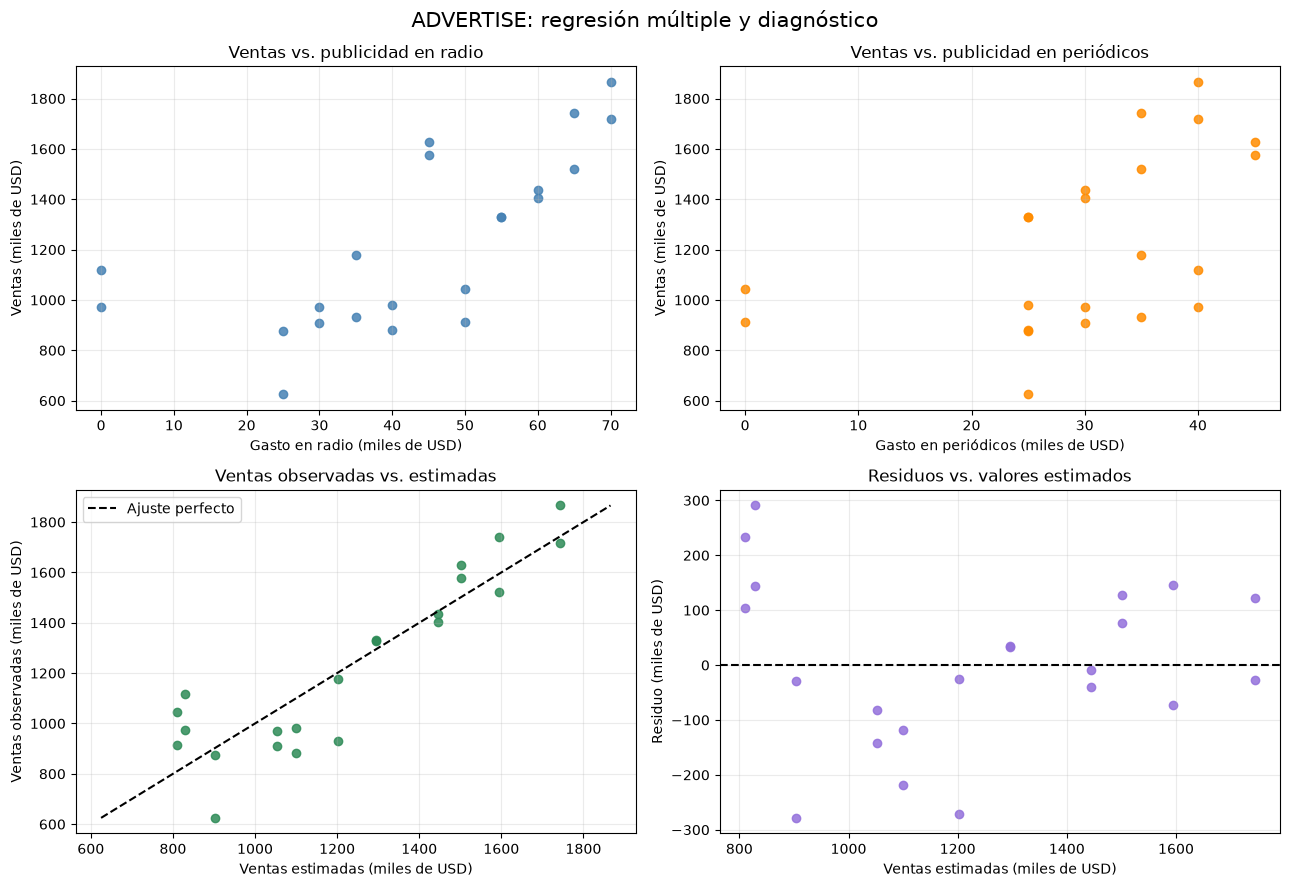

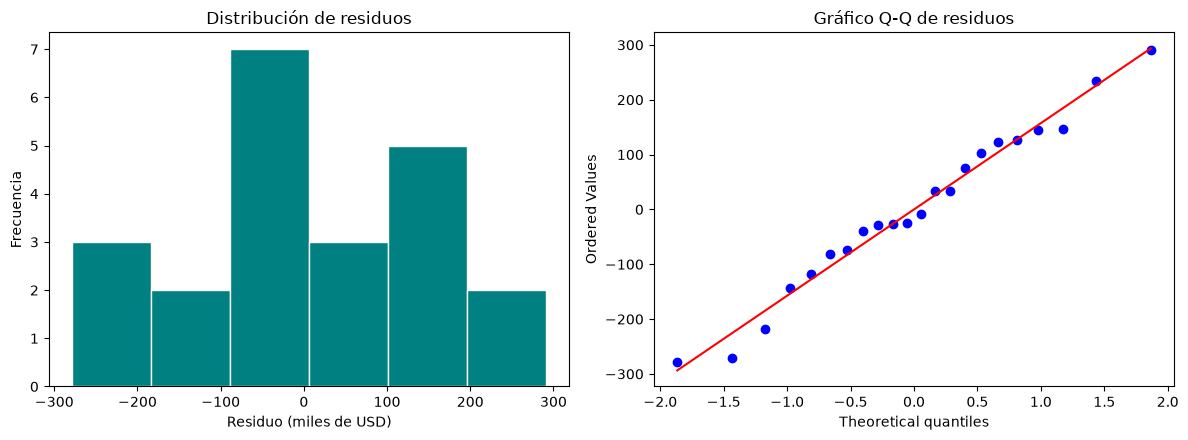

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Busca el archivo tanto si Jupyter inició en la raíz como dentro de Regresion_lineal.
rutas = [Path("Docs/ADVERTISE.xls"), Path("../Docs/ADVERTISE.xls")]
archivo = next((ruta for ruta in rutas if ruta.is_file()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró ADVERTISE.xls. Comprueba que el archivo esté en la carpeta Docs del proyecto."
    )

datos = pd.read_excel(archivo)
columnas = ["Ventas", "Radio", "Periodico"]
faltantes = set(columnas).difference(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en ADVERTISE.xls: {sorted(faltantes)}")
if len(datos) != 22 or datos[columnas].isna().any().any():
    raise ValueError("Se esperaban 22 observaciones completas en Ventas, Radio y Periodico.")

print(f"Archivo: {archivo.resolve()}")
print(f"Ciudades: {len(datos)}")
print("Ventas y gastos publicitarios están expresados en miles de USD.")
display(datos.head())
display(datos.describe().T)

# Regresión múltiple: Ventas = beta_0 + beta_1*Radio + beta_2*Periodico + error.
y = datos["Ventas"].to_numpy(dtype=float)
X = np.column_stack(
    [np.ones(len(datos)), datos["Radio"].to_numpy(dtype=float), datos["Periodico"].to_numpy(dtype=float)]
)
n, k = X.shape
gl_error = n - k
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
ajustados = X @ beta
residuos = y - ajustados
sse = float(residuos @ residuos)
mse = sse / gl_error
cov_beta = mse * np.linalg.inv(X.T @ X)
ee_beta = np.sqrt(np.diag(cov_beta))
t_beta = beta / ee_beta
p_beta = 2 * stats.t.sf(np.abs(t_beta), gl_error)
r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
r2_ajustado = 1 - (1 - r2) * (n - 1) / gl_error

tabla_coeficientes = pd.DataFrame(
    {"Coeficiente": beta, "Error estándar": ee_beta, "t": t_beta, "p-valor": p_beta},
    index=["Intercepto", "Radio (miles de USD)", "Periodico (miles de USD)"],
)
display(tabla_coeficientes)
print(f"R² = {r2:.4f} | R² ajustado = {r2_ajustado:.4f} | Error estándar residual = {np.sqrt(mse):.3f} miles de USD")
print(f"Ecuación estimada: Ventas_hat = {beta[0]:.4f} + {beta[1]:.4f}·Radio + {beta[2]:.4f}·Periodico")

# Intervalo del 95% para la media cuando Radio = 20 y Periodico = 20.
x0 = np.array([1.0, 20.0, 20.0])
media = float(x0 @ beta)
ee_media = np.sqrt(mse * float(x0 @ np.linalg.inv(X.T @ X) @ x0))
t_critico = stats.t.ppf(0.975, gl_error)
li, ls = media - t_critico * ee_media, media + t_critico * ee_media
print("\nRESULTADO: Radio = USD 20,000 y Periódico = USD 20,000")
print(f"Venta media estimada: {media:.3f} miles de USD = USD {media * 1000:,.2f}")
print(f"IC del 95% para la media: [{li:.3f}, {ls:.3f}] miles de USD")
print(f"En dólares: [USD {li * 1000:,.2f}, USD {ls * 1000:,.2f}]")

# Gráficos de dispersión y diagnóstico.
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(datos["Radio"], y, color="steelblue", alpha=0.85)
ax[0, 0].set(title="Ventas vs. publicidad en radio", xlabel="Gasto en radio (miles de USD)", ylabel="Ventas (miles de USD)")
ax[0, 1].scatter(datos["Periodico"], y, color="darkorange", alpha=0.85)
ax[0, 1].set(title="Ventas vs. publicidad en periódicos", xlabel="Gasto en periódicos (miles de USD)", ylabel="Ventas (miles de USD)")
ax[1, 0].scatter(ajustados, y, color="seagreen", alpha=0.85)
extremos = [min(y.min(), ajustados.min()), max(y.max(), ajustados.max())]
ax[1, 0].plot(extremos, extremos, "k--", label="Ajuste perfecto")
ax[1, 0].set(title="Ventas observadas vs. estimadas", xlabel="Ventas estimadas (miles de USD)", ylabel="Ventas observadas (miles de USD)")
ax[1, 0].legend()
ax[1, 1].scatter(ajustados, residuos, color="mediumpurple", alpha=0.85)
ax[1, 1].axhline(0, color="black", linestyle="--")
ax[1, 1].set(title="Residuos vs. valores estimados", xlabel="Ventas estimadas (miles de USD)", ylabel="Residuo (miles de USD)")
for eje in ax.flat:
    eje.grid(alpha=0.25)
fig.suptitle("ADVERTISE: regresión múltiple y diagnóstico", fontsize=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(residuos, bins="auto", edgecolor="white", color="teal")
ax[0].set(title="Distribución de residuos", xlabel="Residuo (miles de USD)", ylabel="Frecuencia")
stats.probplot(residuos, dist="norm", plot=ax[1])
ax[1].set(title="Gráfico Q-Q de residuos")
fig.tight_layout()
plt.show()

## Conclusión

La celda de código imprime la estimación puntual de las ventas medias y su intervalo de confianza del 95%, en miles de dólares y en dólares, para las ciudades con USD 20,000 de publicidad en radio y USD 20,000 en periódicos. La interpretación corresponde a la **media** de las ventas esperada para esas condiciones, no a las ventas de una ciudad específica.